*Credit Card Fraud Detection* is a machine learning classification problem. Its purpose is to identify whether a credit card transaction is legitimate or fraudulent.

Banks and financial institutions process thousands of transactions every second. Some transactions may be unauthorized or suspicious. Machine learning models can analyze transaction patterns and identify potentially fraudulent activity.

In this project, we will train machine learning models to classify transactions into two categories:
- 0 – Legitimate transaction: A normal transaction.
- 1 – Fraudulent transaction: A suspicious or unauthorized transaction.
Objective: Build a machine learning model that can identify fraudulent transactions while minimizing the number of legitimate transactions incorrectly flagged as fraud.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay
)

import joblib

sns.set_theme(style="whitegrid")

In [5]:
DATA_PATH = "creditcard.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  fl

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Class
0    284315
1       492
Name: count, dtype: int64


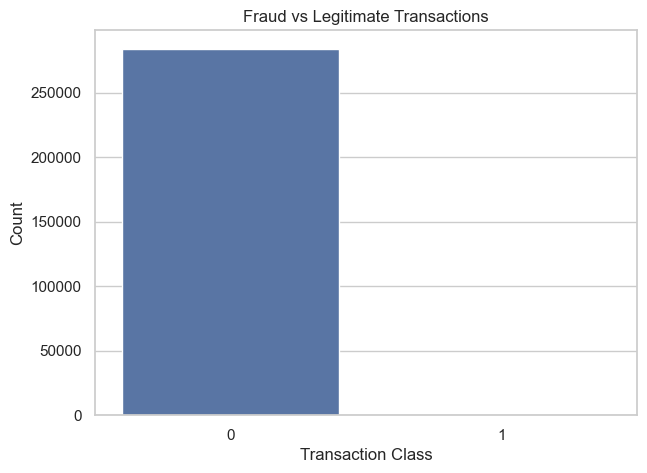

In [7]:
print(df["Class"].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Count")

plt.show()

In [8]:
class_percentage = (
    df["Class"].value_counts(normalize=True) * 100
)

print(class_percentage)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


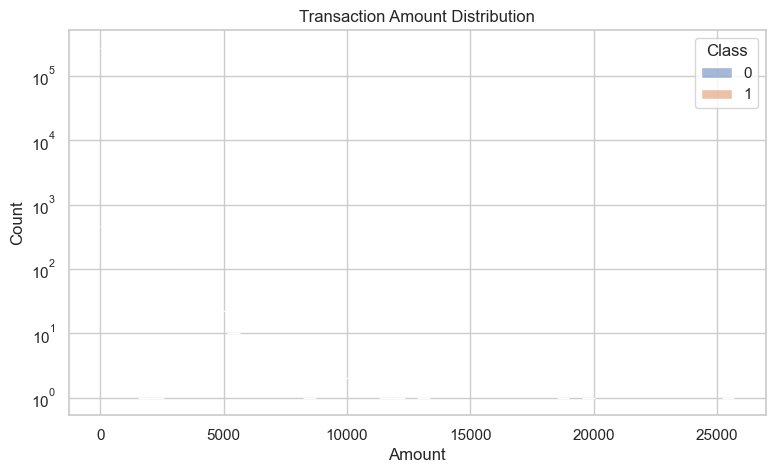

In [9]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    log_scale=(False, True)
)

plt.title("Transaction Amount Distribution")
plt.show()

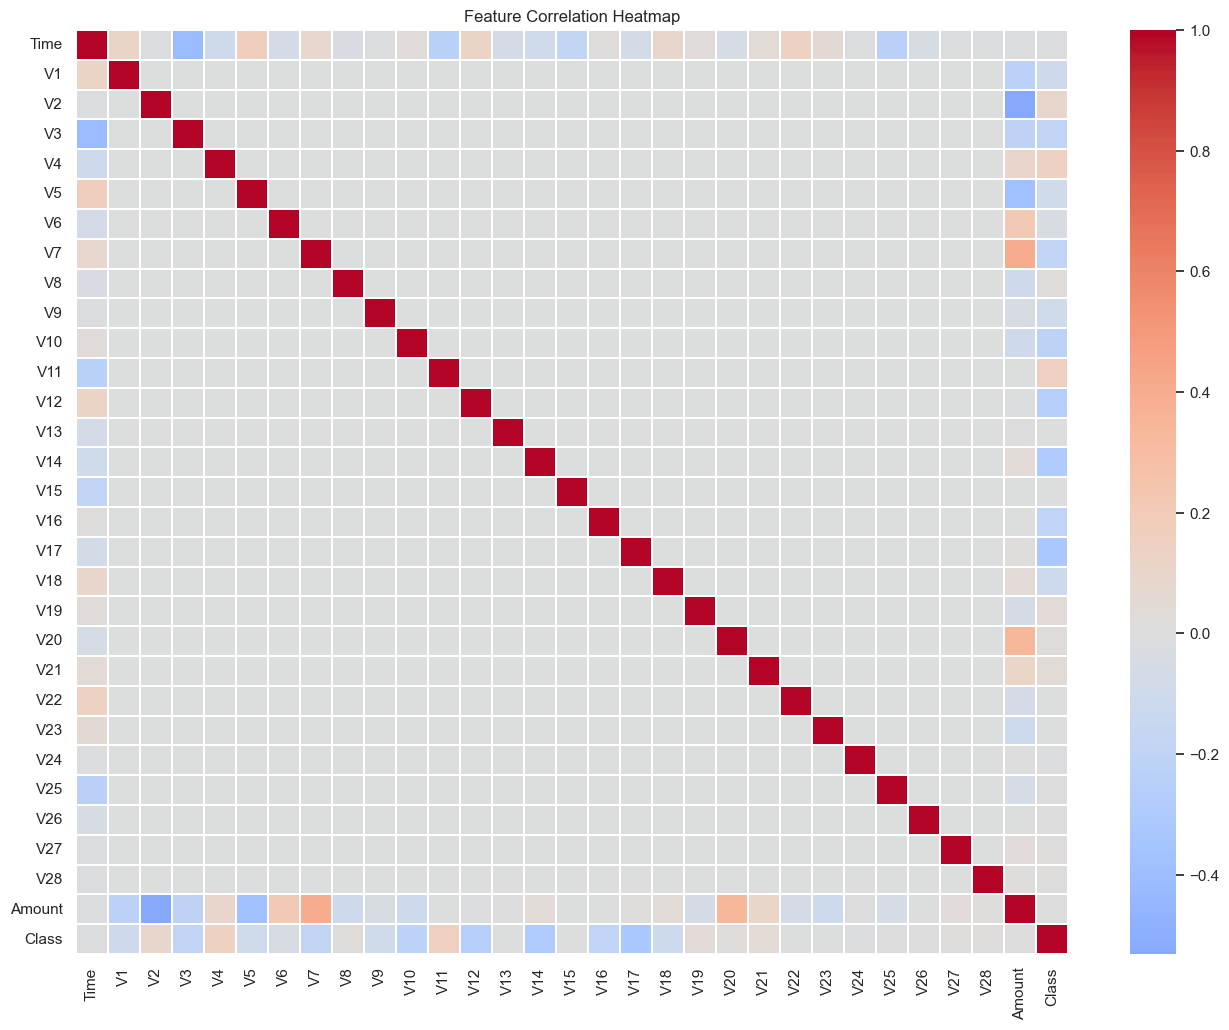

In [10]:
plt.figure(figsize=(16, 12))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [11]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (284807, 30)
Target: (284807,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

Training data: (227845, 30)
Testing data: (56962, 30)

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64


In [13]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), ["Time", "Amount"])
    ],
    remainder="passthrough"
)

In [14]:
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression completed.")

Logistic Regression completed.


In [15]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest completed.")

Random Forest completed.


In [16]:
def evaluate_model(name, y_true, predictions, probabilities):

    print("\n", name)
    print("-" * 45)

    print("Accuracy:", accuracy_score(y_true, predictions))
    print("Precision:", precision_score(y_true, predictions, zero_division=0))
    print("Recall:", recall_score(y_true, predictions, zero_division=0))
    print("F1 Score:", f1_score(y_true, predictions, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_true, probabilities))
    print("PR-AUC:", average_precision_score(y_true, probabilities))

    print("\nClassification Report:")
    print(classification_report(y_true, predictions, zero_division=0))


evaluate_model(
    "Logistic Regression",
    y_test,
    lr_predictions,
    lr_probabilities
)

evaluate_model(
    "Random Forest",
    y_test,
    rf_predictions,
    rf_probabilities
)


 Logistic Regression
---------------------------------------------
Accuracy: 0.9755275446789088
Precision: 0.06097560975609756
Recall: 0.9183673469387755
F1 Score: 0.11435832274459974
ROC-AUC: 0.9721687370080279
PR-AUC: 0.7159122424484009

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962


 Random Forest
---------------------------------------------
Accuracy: 0.9995435553526912
Precision: 0.9615384615384616
Recall: 0.7653061224489796
F1 Score: 0.8522727272727273
ROC-AUC: 0.9628435874208997
PR-AUC: 0.8604126128340365

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.77      0.85 

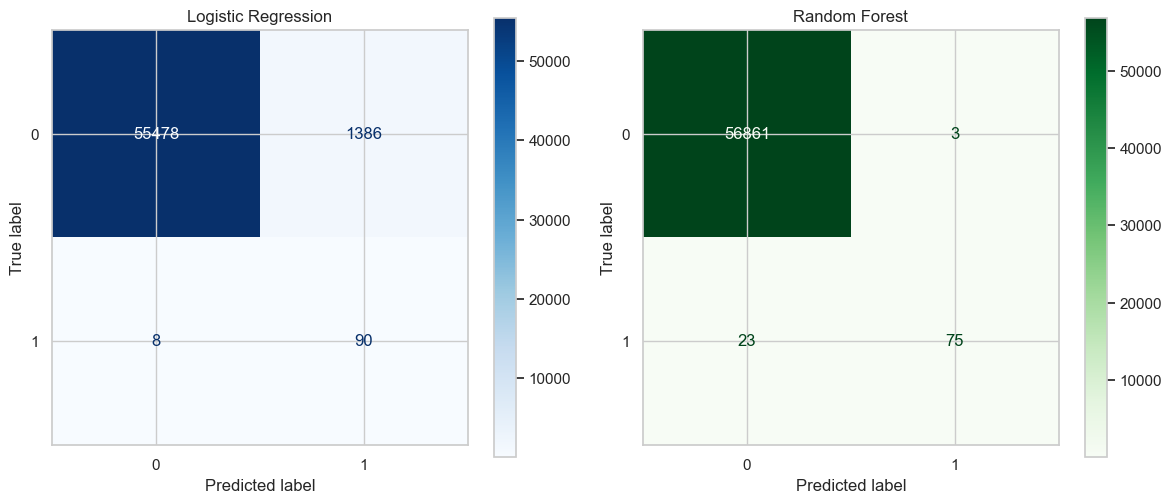

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_predictions,
    ax=axes[0],
    cmap="Blues"
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    ax=axes[1],
    cmap="Greens"
)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

In [18]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, rf_predictions)
    ],

    "Precision": [
        precision_score(y_test, lr_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, lr_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],

    "F1 Score": [
        f1_score(y_test, lr_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],

    "PR-AUC": [
        average_precision_score(y_test, lr_probabilities),
        average_precision_score(y_test, rf_probabilities)
    ]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC
0,Logistic Regression,0.9755,0.0610,0.9184,0.1144,0.7159
1,Random Forest,0.9995,0.9615,0.7653,0.8523,0.8604


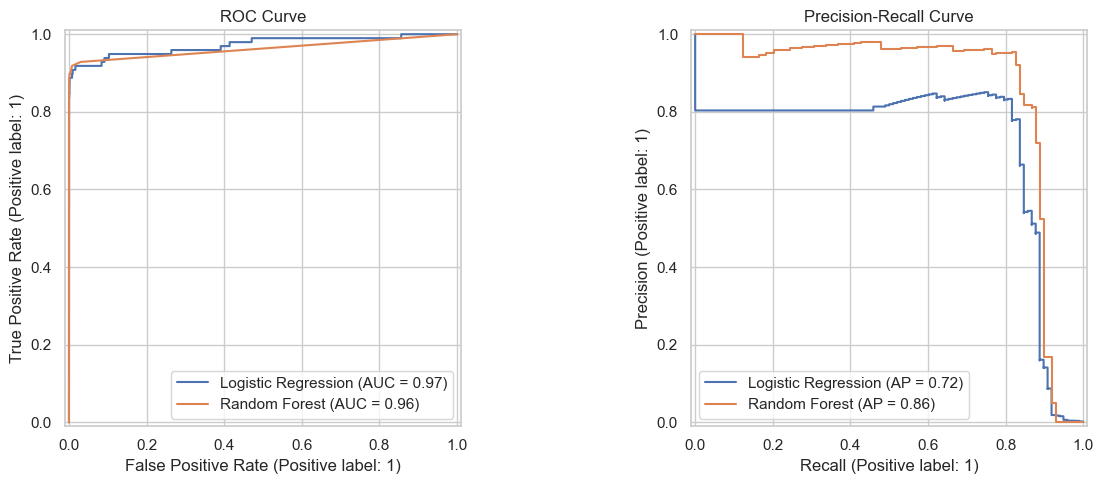

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

RocCurveDisplay.from_predictions(
    y_test, lr_probabilities,
    name="Logistic Regression",
    ax=axes[0]
)

RocCurveDisplay.from_predictions(
    y_test, rf_probabilities,
    name="Random Forest",
    ax=axes[0]
)

axes[0].set_title("ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_test, lr_probabilities,
    name="Logistic Regression",
    ax=axes[1]
)

PrecisionRecallDisplay.from_predictions(
    y_test, rf_probabilities,
    name="Random Forest",
    ax=axes[1]
)

axes[1].set_title("Precision-Recall Curve")

plt.tight_layout()
plt.show()

In [20]:
best_model = (
    rf_model
    if average_precision_score(y_test, rf_probabilities)
       >= average_precision_score(y_test, lr_probabilities)
    else lr_model
)

sample_transaction = X_test.iloc[[0]]

prediction = best_model.predict(sample_transaction)[0]

probability = best_model.predict_proba(sample_transaction)[0][1]

print("Fraud probability:", round(probability, 4))

if prediction == 1:
    print("Result: Potential Fraudulent Transaction")
else:
    print("Result: Likely Legitimate Transaction")

Fraud probability: 0.0
Result: Likely Legitimate Transaction


In [21]:
joblib.dump(best_model, "fraud_detection_model.joblib")

print("Model saved successfully!")

Model saved successfully!
